# 01 — Dataset understanding and exploratory analysis

This notebook builds a careful, evidence-led picture of the credit-card fraud dataset before modeling. It downloads the pinned public dataset only when the local raw CSV is absent. It does not modify or remove observations.


## Business problem and task framing

A payment team may need to prioritize transactions for approval, decline, additional verification, or review. Missing fraud can create losses; flagging legitimate activity can create customer friction. The appropriate operating threshold depends on issuer-specific costs and review capacity, which this dataset does not contain.

The source is the [Kaggle Credit Card Fraud Detection dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). Its description reports 284,807 transactions collected over two days in September 2013, including 492 labeled frauds. Each row is a transaction. `Class` is the target: 0 means legitimate and 1 means fraud. Since `Class` has two possible labels, this is **binary classification, not regression**.

Accuracy alone is not useful under this rare-event prevalence: an all-legitimate prediction could look accurate while detecting no fraud. Keep evaluation at natural prevalence and report Average Precision / PR-AUC, precision, recall, F1 or F2, and confusion matrices. Any threshold or monetary-cost conclusion needs explicit business assumptions.

### Descriptive scope and evaluation boundary

Every plot in this notebook uses the full dataset and is descriptive only. Do not use these plots for model selection, to fit learned transformations, to select a threshold, or to estimate performance. Make development decisions and assess candidate performance with training/validation partitions; never use the held-out test set for selection or threshold tuning. Keep that test partition untouched until the final performance evaluation after choices are frozen.


## Dataset scope and columns

There are 30 numeric input features and one binary target. `V1`–`V28` are anonymized PCA components; their original business meanings are unavailable. `Time` is seconds elapsed since the first transaction, not a calendar timestamp. It cannot identify clock hour, weekday, holidays, or seasonality. `Amount` is transaction amount, not a complete fraud-loss measure. The dataset has no card or customer identifiers, merchant fields, demographic attributes, or behavioral sequence.

| Columns | Role and interpretation |
| --- | --- |
| `Time`, `Amount`, `V1`–`V28` | 30 numeric model inputs |
| `Class` | Binary target: 0 legitimate, 1 fraud |

The evidence supplied for this dataset reports shape 284,807 × 31 and estimated memory use of 70,632,136 bytes. Inputs are floating point, `Class` is integer, and all columns have zero missing values. Exact duplicates total 1,081 rows (0.3796%); there are zero feature-conflicting-target groups. The target is quasi-constant because the legitimate class is 99.83%. These are audit findings, not instructions to delete rows.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')

# Find the repository root whether Jupyter starts in the root or notebooks/.
working_directory = Path.cwd().resolve()
repository_candidates = (working_directory, *working_directory.parents)
REPO_ROOT = next(
    (candidate for candidate in repository_candidates
     if (candidate / 'README.md').is_file() and (candidate / 'notebooks').is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate the repository root from the current working directory.')

RAW_CSV = REPO_ROOT / 'data' / 'raw' / 'creditcard.csv'
print(f'Repository located; expected raw data at {RAW_CSV.relative_to(REPO_ROOT)}')


Repository located; expected raw data at data/raw/creditcard.csv


## Retrieve the pinned source file

The dataset reference is pinned to Kaggle dataset version 3. KaggleHub returns a cache directory; this notebook copies **only** `creditcard.csv` to `data/raw/creditcard.csv`, and only when the destination is absent. No cache path or credential is embedded. The raw data directory is ignored by Git.


In [2]:
import shutil

DATASET_HANDLE = 'mlg-ulb/creditcardfraud/versions/3'
if not RAW_CSV.is_file():
    import kagglehub

    cached_dataset = Path(kagglehub.dataset_download(DATASET_HANDLE))
    cached_csv = cached_dataset / 'creditcard.csv'
    if not cached_csv.is_file():
        raise FileNotFoundError('The pinned Kaggle dataset did not contain creditcard.csv.')
    RAW_CSV.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(cached_csv, RAW_CSV)
    print('Copied the pinned creditcard.csv into data/raw/.')
else:
    print('Using the existing data/raw/creditcard.csv.')


/tmp/opencode/fraud-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Copied the pinned creditcard.csv into data/raw/.


## First look: schema, integrity, and target

These small Pandas checks answer basic questions before any plot or transformation: how much data is present, what columns and types were read, whether missing or repeated rows exist, and how rare the positive class is.


In [3]:
df = pd.read_csv(RAW_CSV)


In [4]:
df.shape


(284807, 31)

In [5]:
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


`df.info()` prints its summary directly and returns `None`; call it by itself rather than wrapping it in `print(df.info())`, which would add an unhelpful `None` line.


In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [7]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [8]:
df.isnull().sum()


Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [9]:
df.duplicated().sum()


np.int64(1081)

In [10]:
df['Class'].value_counts()


Class
0    284315
1       492
Name: count, dtype: int64

In [11]:
df['Class'].value_counts(normalize=True).mul(100).rename('percentage').round(4)


Class
0    99.8273
1     0.1727
Name: percentage, dtype: float64

### Evidence and interpretation

The supplied diagnostic profile reports 284,315 legitimate transactions (99.8273%) and 492 frauds (0.1727%), a severe imbalance. All columns have zero missing values and no co-missing patterns. This does not establish that every unusual value is valid: candidate sentinel-like values are `Time = 999` (2 rows) and `Amount = 999` (7 rows). They are not confirmed missing values; seek domain confirmation rather than recoding them automatically.

The profile reports 1,081 exact duplicate rows (0.3796%) and zero feature-conflicting-target groups. Keep these rows during this audit. Notebook 02 demonstrates why a row-random split can place identical feature signatures on both sides and defines a group-aware holdout without deleting duplicates.


## EDA part 1 — Univariate distributions

Begin with one variable at a time. These plots describe prevalence and input shape; they do not establish predictive value by themselves.


### Class prevalence

- **Question:** How rare is the fraud label in the full dataset?
- **Visualization:** Transaction counts by `Class`, with a logarithmic count axis so the minority class remains visible.
- **Interpretation:** The supplied target profile is 99.8273% Class 0 and 0.1727% Class 1 (492 frauds).
- **Conclusion:** This is severe class imbalance; the majority class dominates raw counts.
- **Model implication:** Keep natural prevalence in validation and test data, and use Average Precision / PR-AUC and class-specific precision and recall rather than accuracy alone.


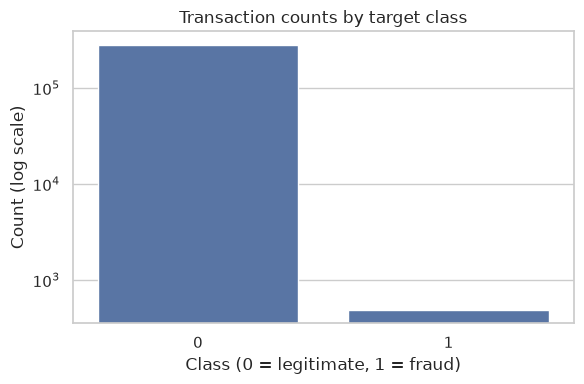

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Class', ax=ax)
ax.set_yscale('log')
ax.set(title='Transaction counts by target class', xlabel='Class (0 = legitimate, 1 = fraud)', ylabel='Count (log scale)')
plt.tight_layout()
plt.show()


### Transaction amount

- **Question:** What does the amount distribution look like, including its long upper tail?
- **Visualization:** Histogram of `log1p(Amount)`; the logarithm compresses the scale without discarding large transactions.
- **Interpretation:** The supplied feature profile reports `Amount.skew = 16.9776`, indicating a strongly right-skewed raw distribution. The transformed axis is for visualization, not a cleaning rule.
- **Conclusion:** A small number of large values can dominate raw-scale plots and distance calculations.
- **Model implication:** Keep the original values for now; standardize numeric inputs inside the training pipeline when using distance-based SMOTE. Consider a transform only as a separately validated modeling choice.


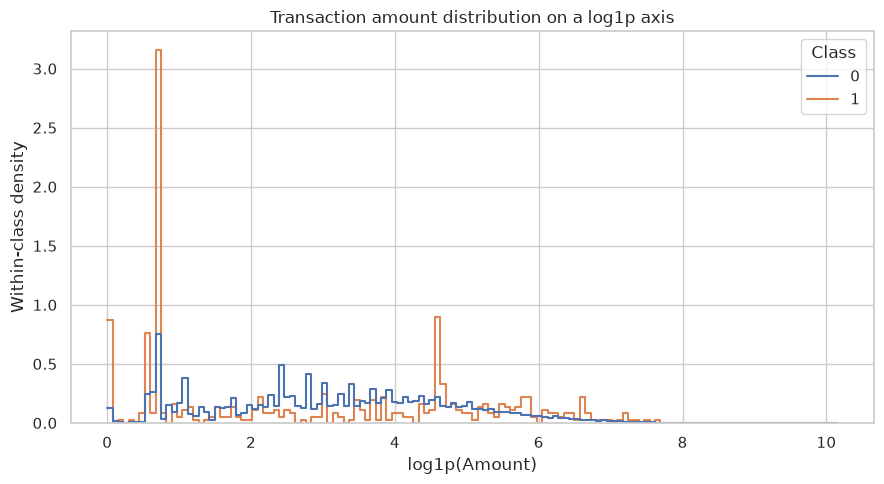

In [13]:
amount_plot = df[['Amount', 'Class']].copy()
amount_plot['log1p_amount'] = np.log1p(amount_plot['Amount'])
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=amount_plot, x='log1p_amount', hue='Class', stat='density', common_norm=False, element='step', fill=False, ax=ax)
ax.set(title='Transaction amount distribution on a log1p axis', xlabel='log1p(Amount)', ylabel='Within-class density')
plt.tight_layout()
plt.show()


### Anonymized PCA component distributions

- **Question:** How do the marginal distributions vary across all 28 anonymized PCA components?
- **Visualization:** A compact 4 × 7 histogram grid covering `V1`–`V28`.
- **Interpretation:** The variables are anonymized PCA components, so their numeric distributions have no supplied direct business interpretation.
- **Conclusion:** Differences in scale or shape may affect distance-based methods and deserve explicit preprocessing.
- **Model implication:** Standardize every numeric input for the SMOTE distance calculation; do not infer business meaning or create categories from component values.


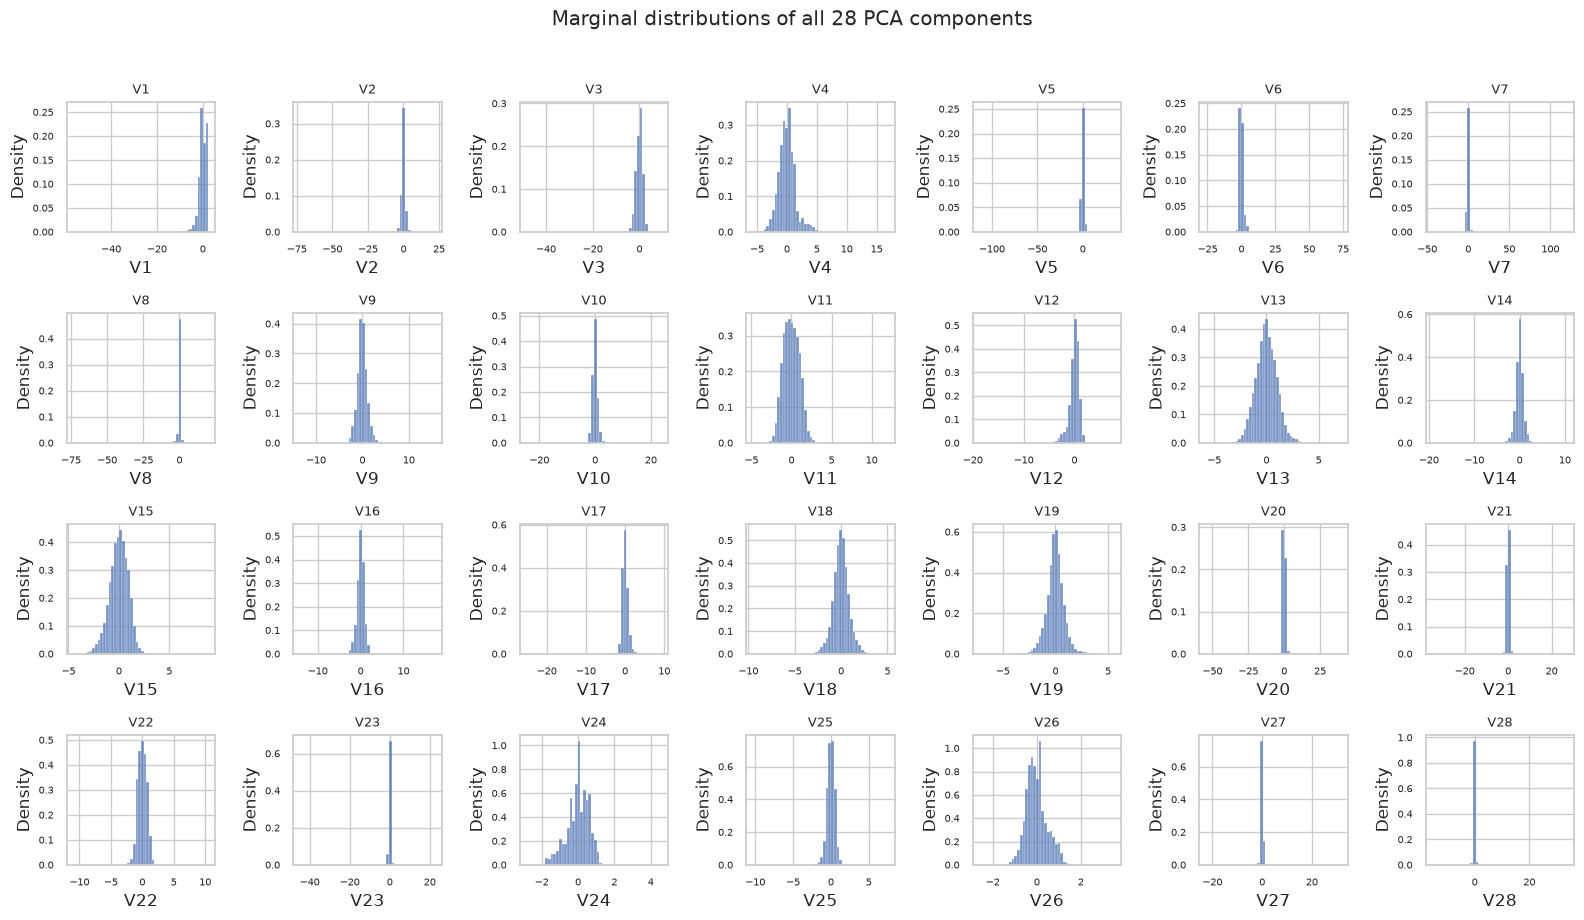

In [14]:
pca_components = [f'V{i}' for i in range(1, 29)]
fig, axes = plt.subplots(4, 7, figsize=(16, 9))
for component, ax in zip(pca_components, axes.flat):
    sns.histplot(data=df, x=component, bins=50, stat='density', ax=ax)
    ax.set_title(component, fontsize=9)
    ax.tick_params(axis='both', labelsize=7)
fig.suptitle('Marginal distributions of all 28 PCA components', y=1.02)
plt.tight_layout()
plt.show()


## EDA part 2 — Bivariate comparisons

Compare inputs with the target to find candidate signals. A visible difference is an association to investigate, not proof of causation or a guarantee of out-of-sample value.


### Amount by class

- **Question:** Does the observed amount distribution differ between legitimate and fraudulent transactions?
- **Visualization:** Box plots of `log1p(Amount)` by `Class`; fliers are displayed rather than removed.
- **Interpretation:** The plot shows descriptive group distributions on a compressed scale; it does not make amount a complete measure of financial loss.
- **Conclusion:** Any apparent separation is a candidate signal that must be checked on held-out data.
- **Model implication:** Preserve the skew and outliers for the baseline experiment; standardize train-fold inputs for SMOTE and select thresholds using validation data at natural prevalence.


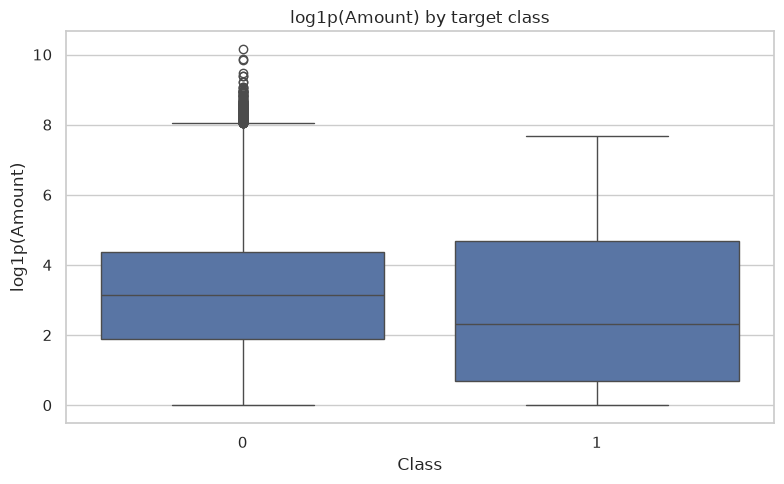

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=amount_plot, x='Class', y='log1p_amount', showfliers=True, ax=ax)
ax.set(title='log1p(Amount) by target class', xlabel='Class', ylabel='log1p(Amount)')
plt.tight_layout()
plt.show()


### Selected PCA components by class

- **Question:** How do several high-association PCA components differ across the two labels?
- **Visualization:** Class-wise box plots for `V14`, `V17`, `V12`, and `V10`; outlier markers are suppressed here for readability and inspected separately in the outlier section.
- **Interpretation:** The supplied Pearson associations with `Class` are V17 = -0.3265, V14 = -0.3025, V12 = -0.2606, and V10 = -0.2169. These are associations, not causal effects.
- **Conclusion:** These components merit validation as candidate predictors, but their anonymized values do not explain business mechanisms.
- **Model implication:** Compare models on a held-out set and report ranking and threshold metrics; do not select features from this plot alone.


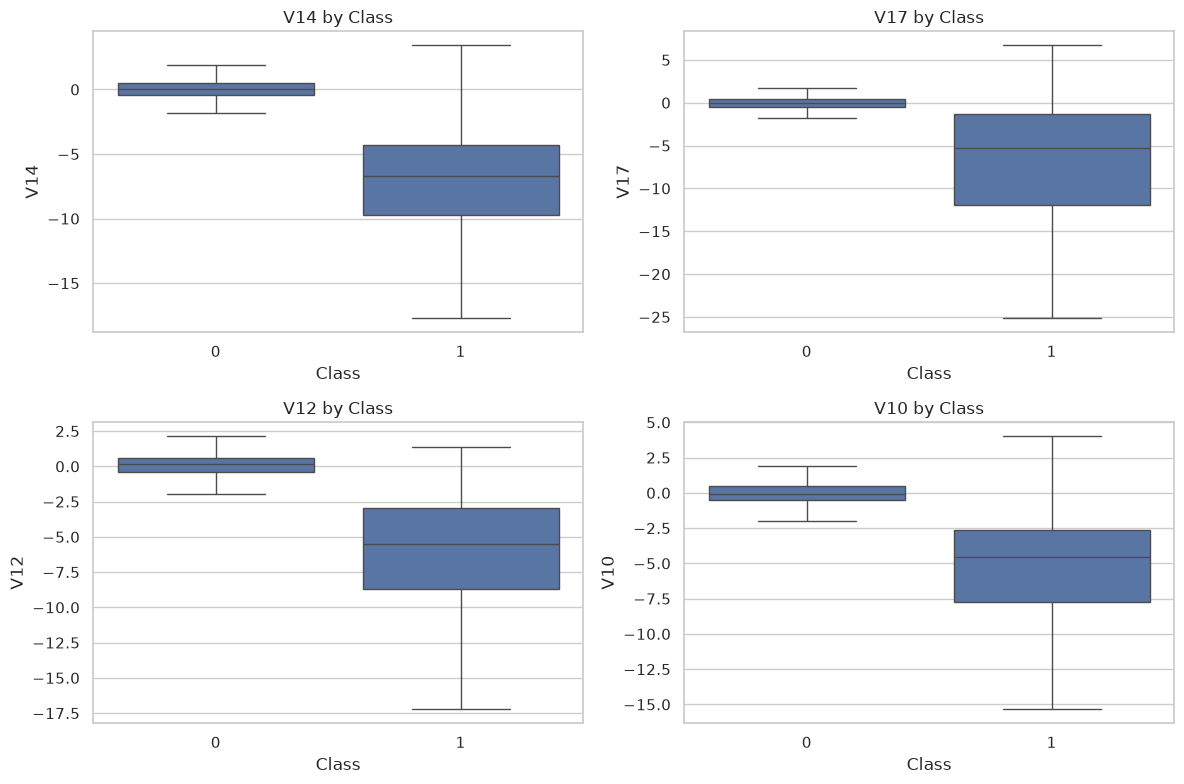

In [16]:
selected_components = ['V14', 'V17', 'V12', 'V10']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for component, ax in zip(selected_components, axes.flat):
    sns.boxplot(data=df, x='Class', y=component, showfliers=False, ax=ax)
    ax.set_title(f'{component} by Class')
plt.tight_layout()
plt.show()


### Single-feature association with the target

- **Question:** Which numeric features have the largest absolute Pearson association with `Class`?
- **Visualization:** Sorted horizontal bars of feature-to-target Pearson correlations.
- **Interpretation:** The reported strongest absolute associations include V17, V14, V12, and V10, all below an absolute correlation of 0.33. Correlation measures association, not causation, and can miss nonlinear patterns.
- **Conclusion:** No single reported association establishes a useful or leakage-free model.
- **Model implication:** Treat these as inspection priorities; assess performance only on appropriately separated data.


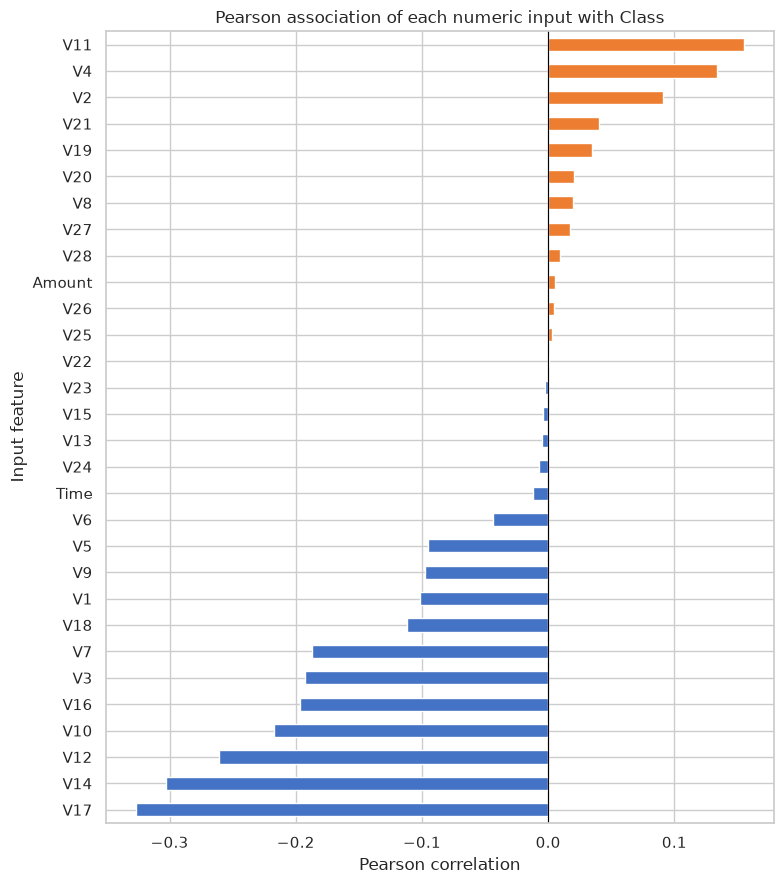

In [17]:
target_correlations = df.corr(numeric_only=True)['Class'].drop('Class').sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
target_correlations.plot(kind='barh', ax=ax, color=np.where(target_correlations < 0, '#4472C4', '#ED7D31'))
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Pearson association of each numeric input with Class', xlabel='Pearson correlation', ylabel='Input feature')
plt.tight_layout()
plt.show()


## EDA part 3 — Multivariate relationships

A correlation matrix summarizes pairwise linear association across inputs and target. The supplied feature-signal scan found no collinear pairs at its absolute-correlation threshold of 0.90.


### Correlation heatmap

- **Question:** Are there strong pairwise linear associations among the input features, and how do inputs associate with `Class`?
- **Visualization:** Pearson correlation heatmap for all numeric inputs and the binary target.
- **Interpretation:** A heatmap is a compact association summary. The reported scan found no feature pairs meeting |r| ≥ 0.90; target correlations remain associations, not causal effects.
- **Conclusion:** No pair is flagged for automatic removal by the supplied collinearity audit.
- **Model implication:** Keep the feature set for baseline comparison; use validation rather than correlation alone to decide whether any simplification helps.


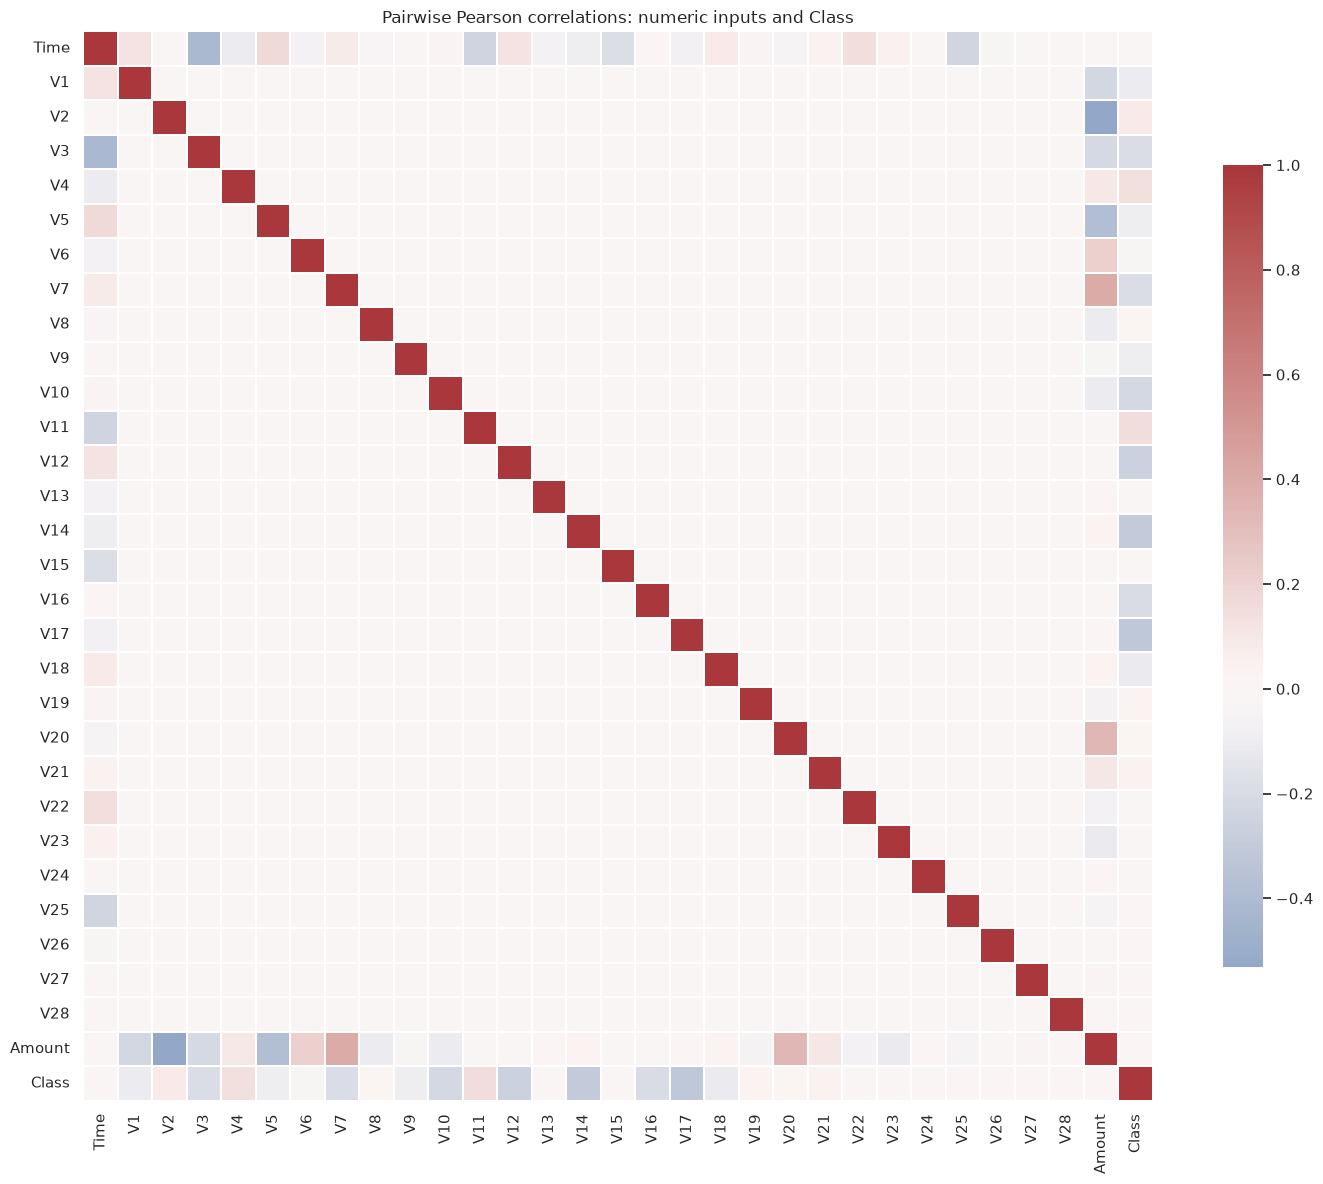

In [18]:
correlation_matrix = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(correlation_matrix, cmap='vlag', center=0, square=True, linewidths=0.1, cbar_kws={'shrink': 0.75}, ax=ax)
ax.set_title('Pairwise Pearson correlations: numeric inputs and Class')
plt.tight_layout()
plt.show()


## EDA part 4 — Relative elapsed-time pattern

`Time` is elapsed seconds from the first transaction. The chart below groups it into relative elapsed hours; it does not represent clock time. The supplied scan reports no calendar date column, so no calendar-hour or weekday conclusions are supported.


### Counts and fraud rate by relative elapsed hour

- **Question:** How do transaction volume, fraud counts, and fraud rate vary across relative elapsed-hour bins?
- **Visualization:** Two panels show transaction and fraud counts (with separate count axes) and fraud rate per transaction.
- **Interpretation:** This is a descriptive pattern over the dataset's collection window. `Time` is elapsed seconds, not a calendar timestamp; no calendar-hour or weekday conclusions are supported.
- **Conclusion:** Local variation cannot establish temporal generalization or calendar-time behavior.
- **Model implication:** Do not engineer calendar features from `Time`; temporal validation can be considered later as a limited historical simulation, with the dataset's short time span stated.


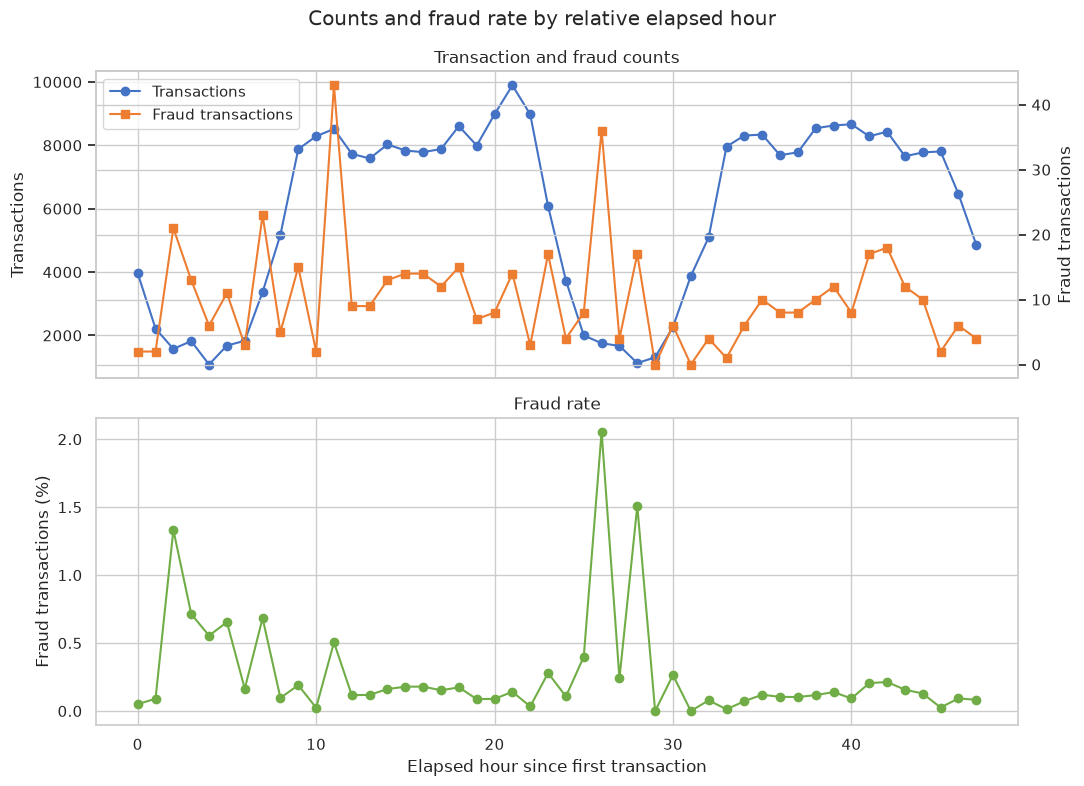

In [19]:
relative_hour = (df['Time'] // 3600).astype(int).rename('elapsed_hour')
hourly_summary = df.groupby(relative_hour).agg(
    transaction_count=('Class', 'size'),
    fraud_count=('Class', 'sum'),
)
hourly_summary['fraud_rate_pct'] = 100 * hourly_summary['fraud_count'] / hourly_summary['transaction_count']
hourly_summary = hourly_summary.reset_index()
fig, (count_ax, rate_ax) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
transaction_line, = count_ax.plot(
    hourly_summary['elapsed_hour'], hourly_summary['transaction_count'],
    marker='o', color='#4472C4', label='Transactions',
)
count_ax.set_ylabel('Transactions')
count_ax.set_title('Transaction and fraud counts')
fraud_count_ax = count_ax.twinx()
fraud_line, = fraud_count_ax.plot(
    hourly_summary['elapsed_hour'], hourly_summary['fraud_count'],
    marker='s', color='#ED7D31', label='Fraud transactions',
)
fraud_count_ax.set_ylabel('Fraud transactions')
count_ax.legend(
    [transaction_line, fraud_line],
    [transaction_line.get_label(), fraud_line.get_label()],
    loc='upper left',
)
rate_ax.plot(
    hourly_summary['elapsed_hour'], hourly_summary['fraud_rate_pct'],
    marker='o', color='#70AD47',
)
rate_ax.set(title='Fraud rate', xlabel='Elapsed hour since first transaction', ylabel='Fraud transactions (%)')
fig.suptitle('Counts and fraud rate by relative elapsed hour')
plt.tight_layout()
plt.show()


## EDA part 5 — IQR outlier inspection

An IQR flag is a descriptive rule, not proof of an invalid observation. The supplied scan reports IQR outliers; inspect them in context, and do not automatically remove or cap them. Exact duplicate rows should likewise be retained unless a documented downstream decision says otherwise.


### IQR-flagged values across numeric inputs

- **Question:** Which numeric inputs have values outside the univariate 1.5 × IQR fences?
- **Visualization:** Percentage of rows outside each feature's Tukey fences, sorted for comparison.
- **Interpretation:** The flags identify values for inspection; they do not distinguish valid rare transactions from data errors. The supplied scan also identifies candidate sentinel-like values `Time = 999` (2) and `Amount = 999` (7), neither confirmed as missing.
- **Conclusion:** Keep all rows and raw values during this learning audit; request domain confirmation for suspicious values.
- **Model implication:** Do not fit an outlier-removal rule on the full dataset. If a transformation or robust method is later evaluated, fit any learned preprocessing on training folds only.


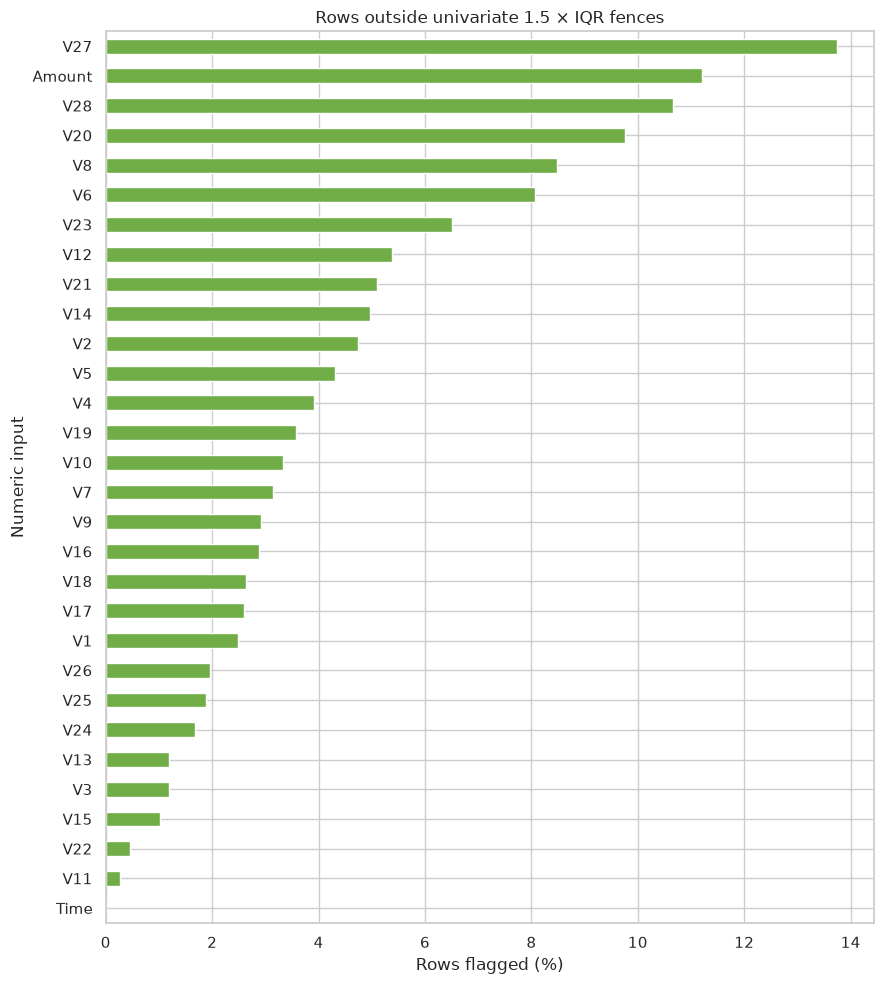

In [20]:
numeric_inputs = df.drop(columns=['Class']).select_dtypes(include='number')
q1 = numeric_inputs.quantile(0.25)
q3 = numeric_inputs.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outlier_counts = numeric_inputs.lt(lower_fence) | numeric_inputs.gt(upper_fence)
outlier_summary = pd.DataFrame({
    'outlier_count': outlier_counts.sum(),
    'outlier_pct': 100 * outlier_counts.mean(),
}).sort_values('outlier_pct')
fig, ax = plt.subplots(figsize=(9, 10))
outlier_summary['outlier_pct'].plot(kind='barh', ax=ax, color='#70AD47')
ax.set(title='Rows outside univariate 1.5 × IQR fences', xlabel='Rows flagged (%)', ylabel='Numeric input')
plt.tight_layout()
plt.show()


### Class-wise comparison of flagged inputs

- **Question:** Do amount and a flagged PCA component show different central ranges or extreme values across the two classes?
- **Visualization:** A class-wise quantile table plus box plots for `log1p(Amount)` and `V27`; boxplot outlier markers are suppressed for readability, while the table reports upper quantiles and maxima.
- **Interpretation:** The supplied audit flags IQR outliers in `Amount` and `V27` (`eda-missingness-audit.outliers_iqr.Amount=31904`; `eda-missingness-audit.outliers_iqr.V27=39163`). Compare the displayed class-specific medians, upper quantiles, and maxima; these are descriptive differences, not proof of invalid values or causation.
- **Conclusion:** Extreme values and class differences require inspection; they are not automatic cleaning instructions.
- **Model implication:** Keep observations for the baseline, and evaluate any robust scaling or transformation using training folds only. These full-dataset comparisons are descriptive only.


In [21]:
class_outlier_comparison = df[['Amount', 'V27', 'Class']].copy()
class_outlier_comparison['log1p_Amount'] = np.log1p(class_outlier_comparison['Amount'])
class_extreme_summary = class_outlier_comparison.groupby('Class').agg(
    amount_median=('Amount', 'median'),
    amount_p99=('Amount', lambda values: values.quantile(0.99)),
    amount_max=('Amount', 'max'),
    v27_median=('V27', 'median'),
    v27_p99=('V27', lambda values: values.quantile(0.99)),
    v27_max=('V27', 'max'),
)
class_extreme_summary


,amount_median,amount_p99,amount_max,v27_median,v27_p99,v27_max
Class,,,,,,
0,22.00,1016.9664,25691.16,0.001230,0.915308,31.612198
1,9.25,1357.4279,2125.87,0.394926,2.246698,3.052358


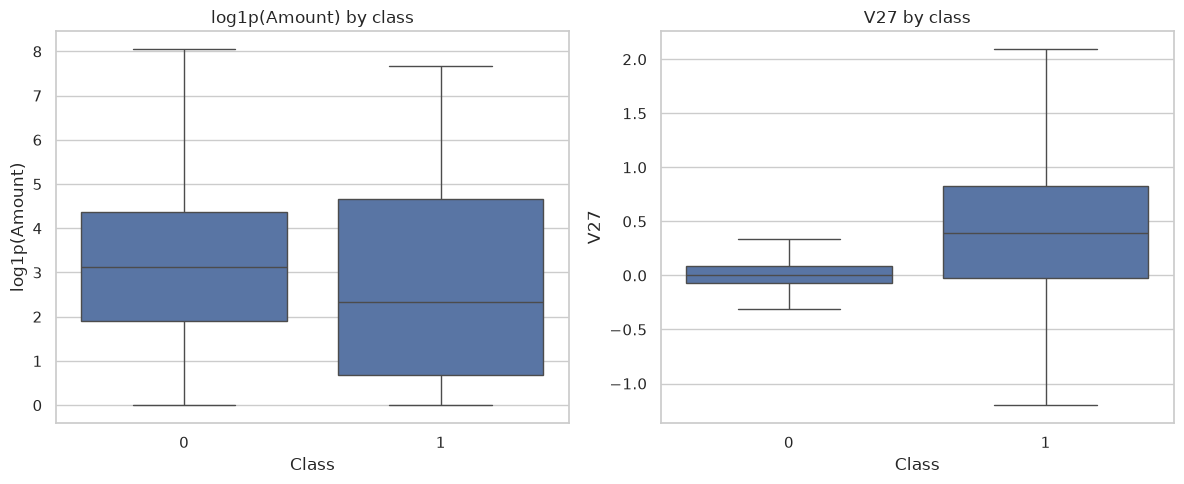

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(
    data=class_outlier_comparison, x='Class', y='log1p_Amount',
    showfliers=False, ax=axes[0],
)
axes[0].set(title='log1p(Amount) by class', xlabel='Class', ylabel='log1p(Amount)')
sns.boxplot(
    data=class_outlier_comparison, x='Class', y='V27',
    showfliers=False, ax=axes[1],
)
axes[1].set(title='V27 by class', xlabel='Class', ylabel='V27')
plt.tight_layout()
plt.show()


## EDA conclusions and modeling implications

- The target is binary and severely imbalanced: use natural-prevalence validation/test sets and report Average Precision / PR-AUC, precision, recall, F2, and confusion matrices—not accuracy alone.
- No columns are missing, but candidate sentinel values, IQR outliers, and exact duplicates warrant transparent review rather than automatic correction.
- PCA components are anonymized. Their observed correlations with fraud are associations and do not reveal causal or business explanations.
- `Time` is relative elapsed time over two days, not a calendar field. No calendar-hour or weekday conclusions are supported.
- The supplied leakage scan reports row-index/target correlation -0.0117, no group keys, no calendar date columns, and unknown train/test drift because no separate test CSV is available. A moderate single-feature result such as V14 AUC 0.9492 is not proof of leakage.
- The supplied scan's generic CV recommendation is StratifiedKFold. Because exact-feature signatures cross a conventional row split, Notebook 02 uses a group-aware holdout; choose the next-phase CV protocol with both class stratification and duplicate grouping in mind.
- For distance-based oversampling, standardize all numeric inputs using training data only. Notebook 02 demonstrates a grouped holdout that keeps identical feature signatures together; duplicates are not deleted.
- Full-dataset plots in this notebook are descriptive only. During development, use training/validation partitions for model selection, learned transformations, threshold selection, and candidate performance assessment. Do not use the held-out test set for any of those decisions; reserve it for the final performance evaluation after the approach is frozen.

This dataset is a historical learning benchmark from two days in 2013. It cannot establish current production performance, issuer-specific costs, customer-level behavior, or robust generalization to other periods and populations.
